# Experiment 14 — Install Apache Spark and Explore Core Features

**Aim:** Start Apache Spark locally with PySpark and demonstrate structured-data transformations and actions.

**Libraries / software:** Python, PySpark, Java 17 or 21 compatible with the selected Spark release, pandas, Matplotlib, and Jupyter. The local execution mode is not a distributed cluster.

**Installation:** Install the Python package with `python -m pip install pyspark==4.3.0`; also install/configure a compatible Java runtime.

**Theory:** Spark DataFrames describe structured data. Transformations such as `select`, `filter`, and `groupBy` are evaluated lazily; an action such as `show` or `count` triggers computation.

**Procedure / Implementation:** Create a Spark session, load a small CSV with an explicit schema, inspect the schema, select/filter records, aggregate sales, compare the result with pandas, and stop the session.

**Dataset:** A clearly labeled, synthetic transaction table is generated in the notebook so the demonstration is reproducible and contains no personal data. Replace it with an instructor-approved candidate-unique dataset when required.

## Procedure / Implementation — Create a local Spark session and sample CSV

In [1]:
from pathlib import Path
import pandas as pd

import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum as spark_sum
from pyspark.sql.types import DoubleType, StringType, StructField, StructType

ROOT = Path.cwd()
DATA_PATH = ROOT / "outputs" / "results" / "exp14_spark_transactions.csv"
FIGURES = ROOT / "outputs" / "figures"
RESULTS = ROOT / "outputs" / "results"
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

transactions = pd.DataFrame(
    [
        ("North", "Notebook", 3, 4.50),
        ("North", "Pen", 10, 1.20),
        ("South", "Notebook", 5, 4.50),
        ("South", "Folder", 4, 2.75),
        ("West", "Pen", 8, 1.20),
        ("West", "Folder", 6, 2.75),
        ("East", "Notebook", 2, 4.50),
        ("East", "Pen", 12, 1.20),
    ],
    columns=["region", "product", "quantity", "unit_price"],
)
transactions["amount"] = transactions["quantity"] * transactions["unit_price"]
transactions.to_csv(DATA_PATH, index=False)

schema = StructType(
    [
        StructField("region", StringType(), False),
        StructField("product", StringType(), False),
        StructField("quantity", DoubleType(), False),
        StructField("unit_price", DoubleType(), False),
        StructField("amount", DoubleType(), False),
    ]
)
spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("IT411-Experiment-14")
    .config("spark.ui.enabled", "false")
    .getOrCreate()
)
print("Spark version:", spark.version)
print("Execution mode: local[2]")

Spark version: 4.3.0
Execution mode: local[2]


## 2. Demonstrate DataFrame transformations and actions

Schema:
root
 |-- region: string (nullable = true)
 |-- product: string (nullable = true)
 |-- quantity: double (nullable = true)
 |-- unit_price: double (nullable = true)
 |-- amount: double (nullable = true)

Rows:


+------+--------+--------+----------+------------------+
|region|product |quantity|unit_price|amount            |
+------+--------+--------+----------+------------------+
|North |Notebook|3.0     |4.5       |13.5              |
|North |Pen     |10.0    |1.2       |12.0              |
|South |Notebook|5.0     |4.5       |22.5              |
|South |Folder  |4.0     |2.75      |11.0              |
|West  |Pen     |8.0     |1.2       |9.6               |
|West  |Folder  |6.0     |2.75      |16.5              |
|East  |Notebook|2.0     |4.5       |9.0               |
|East  |Pen     |12.0    |1.2       |14.399999999999999|
+------+--------+--------+----------+------------------+

Filtered rows with amount >= 10:


+------+--------+------------------+
|region|product |amount            |
+------+--------+------------------+
|North |Notebook|13.5              |
|North |Pen     |12.0              |
|South |Notebook|22.5              |
|South |Folder  |11.0              |
|West  |Folder  |16.5              |
|East  |Pen     |14.399999999999999|
+------+--------+------------------+



Action count: 8


+------+-----------+
|region|total_sales|
+------+-----------+
|East  |23.4       |
|North |25.5       |
|South |33.5       |
|West  |26.1       |
+------+-----------+



,region,spark_total_sales,pandas_total_sales,matches
0,East,23.4,23.4,True
1,North,25.5,25.5,True
2,South,33.5,33.5,True
3,West,26.1,26.1,True


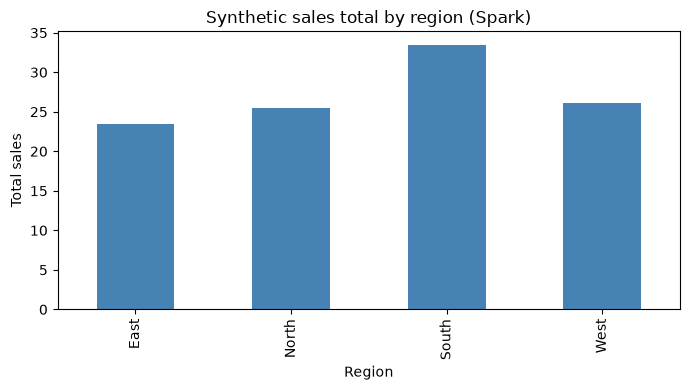

Spark session stopped.


In [2]:
try:
    frame = spark.read.csv(str(DATA_PATH), header=True, schema=schema)
    print("Schema:")
    frame.printSchema()
    print("Rows:")
    frame.show(truncate=False)

    selected = frame.select("region", "product", "amount").filter(col("amount") >= 10)
    print("Filtered rows with amount >= 10:")
    selected.show(truncate=False)

    by_region = (
        frame.groupBy("region")
        .agg(spark_sum("amount").alias("total_sales"))
        .orderBy("region")
    )
    print("Action count:", frame.count())
    by_region.show(truncate=False)

    spark_result = pd.DataFrame(
        [(row["region"], row["total_sales"]) for row in by_region.collect()],
        columns=["region", "spark_total_sales"],
    )
    pandas_result = (
        transactions.groupby("region", as_index=False)["amount"]
        .sum()
        .rename(columns={"amount": "pandas_total_sales"})
    )
    comparison = spark_result.merge(pandas_result, on="region")
    comparison["matches"] = comparison["spark_total_sales"].round(8) == comparison["pandas_total_sales"].round(8)
    assert comparison["matches"].all()
    comparison.to_csv(RESULTS / "exp14_spark_region_totals.csv", index=False)
    display(comparison)

    ax = comparison.set_index("region")["spark_total_sales"].plot(
        kind="bar", figsize=(7, 4), color="steelblue"
    )
    ax.set_title("Synthetic sales total by region (Spark)")
    ax.set_xlabel("Region")
    ax.set_ylabel("Total sales")
    plt.tight_layout()
    plt.savefig(FIGURES / "exp14_spark_sales.png", dpi=150, bbox_inches="tight")
    plt.show()
finally:
    spark.stop()
    print("Spark session stopped.")

## Observation
The notebook prints the schema, rows, filtered result, aggregate result, count action, and a Spark-versus-pandas comparison. The assertion verifies that the two implementations agree on this small sample.

## Result
The demonstrated transformations and action completed in Spark local mode. This validates the local PySpark setup and does not establish distributed-cluster performance.